# Approach C — Ordinal many-facet model (Bayesian MFRM, rating-scale type)

Part of the approach series described in [`../APPROACHES.md`](../APPROACHES.md).

**Idea.** Many-facet Rasch measurement (Linacre, 1989; Eckes, 2015) places
actions (creativity θ) and raters (severity λ) on a **common logit scale**,
and treats the 1–7 ratings as **ordered categories** with shared category
thresholds τ (the rating-scale structure; Andrich, 1978). The ordinal link
respects that the scale is bounded and that the distances between categories
need not be equal. Primi et al. (2019) applied this framework to creativity
ratings.

This notebook estimates the cumulative-logit version of the model as a
Bayesian hierarchical model in PyMC. Classical MFRM software (FACETS, `TAM`,
`sirt`) uses the adjacent-category (Rasch) link instead. Both share the same
facet structure, and in practice their estimates are closely related.
`02_creativity_ratings_R.qmd` contains a `sirt::rm.facets` fit for comparison.

**This notebook computes**
- the model, with convergence diagnostics and posterior predictive checks,
- latent action scores θ (with credible intervals, posterior ranks, and the
  expected rating on the 1–7 scale),
- rater severity λ,
- Rasch-style **infit/outfit** fit statistics for raters (and actions),
- **separation reliability** for actions and raters.

**Assumptions and limits.** All raters share the same thresholds and the same
discrimination: they differ only by a shift on the logit scale. Relaxing the
equal-discrimination assumption gives the JRT model in `02d`.

**Outputs:** `results/tables/scores_mfrm.csv`, `raters_mfrm.csv`,
`model_diagnostics_mfrm.csv`, `results/models/ordinal_crossed_model.nc`
(including the pointwise log-likelihood, which `02d` uses for LOO).

## 0. Setup, reproducibility, and session information

In [1]:
import warnings
import platform
import subprocess
import sys
import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

NOTEBOOK_KEY = "mfrm"
SEED = 20260713
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# ------------------------------------------------------------------
# Project paths (relative to the notebook folder "notebooks/")
# ------------------------------------------------------------------
PROJECT_ROOT = Path("..").resolve()
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
RESULTS_TABLES = PROJECT_ROOT / "results" / "tables"
RESULTS_FIGURES = PROJECT_ROOT / "results" / "figures"
RESULTS_MODELS = PROJECT_ROOT / "results" / "models"
RESULTS_LOGS = PROJECT_ROOT / "results" / "logs"

for d in [DATA_PROCESSED, RESULTS_TABLES, RESULTS_FIGURES, RESULTS_MODELS, RESULTS_LOGS]:
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

warnings.filterwarnings("default", category=UserWarning)

def save_fig(fig, name, caption=None):
    # Saves a figure as PNG and SVG under results/figures/.
    fig.savefig(RESULTS_FIGURES / f"{name}.png", bbox_inches="tight")
    fig.savefig(RESULTS_FIGURES / f"{name}.svg", bbox_inches="tight")
    if caption:
        (RESULTS_FIGURES / f"{name}_caption.txt").write_text(caption)
    print(f"Figure saved: {name}.png / {name}.svg")

def save_table(df_table, name, index=False):
    # Saves a table as CSV under results/tables/.
    path = RESULTS_TABLES / f"{name}.csv"
    df_table.to_csv(path, index=index)
    print(f"Table saved: {path.relative_to(PROJECT_ROOT)} "
          f"({df_table.shape[0]} rows x {df_table.shape[1]} columns)")
    return path

def save_diagnostics(values):
    # Scalar results (reliability, convergence, ...) for 03_approach_comparison.ipynb.
    out = pd.DataFrame({"quantity": list(values), "value": [float(v) for v in values.values()]})
    return save_table(out, f"model_diagnostics_{NOTEBOOK_KEY}")

WARNINGS_LOG = []
def log_warning(msg):
    # No silent failures: warnings are collected and exported at the end of the notebook.
    WARNINGS_LOG.append({"notebook": NOTEBOOK_KEY,
                         "timestamp": datetime.now(timezone.utc).isoformat(),
                         "message": msg})
    warnings.warn(msg)

print(f"Seed: {SEED}")
print(f"Project root: {PROJECT_ROOT}")

Seed: 20260713
Project root: /home/max/drive/projects/3_Creativity/11-paper-CAT-methodology/data-analysis/creativity-ratings-psychometrics


In [2]:
def get_git_hash():
    try:
        out = subprocess.run(["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT,
                             capture_output=True, text=True, timeout=5)
        if out.returncode == 0:
            return out.stdout.strip()
    except Exception:
        pass
    return "not available"

session_info = {
    "notebook": NOTEBOOK_KEY,
    "analysis_datetime_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version,
    "platform": platform.platform(),
    "git_commit": get_git_hash(),
    "seed": SEED,
    "package_versions": {},
}
for pkg_name in ['numpy', 'pandas', 'scipy', 'matplotlib', 'networkx', 'pymc', 'arviz']:
    try:
        mod = __import__(pkg_name)
        session_info["package_versions"][pkg_name] = getattr(mod, "__version__", "unknown")
    except ImportError:
        session_info["package_versions"][pkg_name] = "not installed"

with open(RESULTS_LOGS / f"session_info_{NOTEBOOK_KEY}.json", "w") as f:
    json.dump(session_info, f, indent=2)
print(json.dumps(session_info["package_versions"], indent=2))

{
  "numpy": "2.4.6",
  "pandas": "3.0.3",
  "scipy": "1.18.0",
  "matplotlib": "3.11.0",
  "networkx": "3.6.1",
  "pymc": "6.1.0",
  "arviz": "1.2.0"
}


## 1. Data

Loads the cleaned ratings from `00_data_loading_preprocessing.ipynb`
(`data/processed/ratings_long_clean.csv`) and flags the largest connected
component of the rater–action graph. This block is identical in all approach
notebooks so that each notebook runs on its own.

In [3]:
CLEAN_PATH = DATA_PROCESSED / "ratings_long_clean.csv"
if not CLEAN_PATH.exists():
    raise FileNotFoundError(f"{CLEAN_PATH} not found. Run 00_data_loading_preprocessing.ipynb first.")

ratings_clean = pd.read_csv(CLEAN_PATH)
ratings_clean["action_id"] = ratings_clean["action_id"].astype(str)
ratings_clean["rater_id"] = ratings_clean["rater_id"].astype(str)

required_cols = ["action_id", "rater_id", "rating_numeric"]
missing_cols = [c for c in required_cols if c not in ratings_clean.columns]
if missing_cols:
    raise ValueError(f"Required variables missing from the preprocessed dataset: {missing_cols}")
assert ratings_clean["rating_numeric"].between(1, 7).all(), "Ratings outside 1-7!"
assert not ratings_clean.duplicated(subset=["action_id", "rater_id"]).any(), "Duplicate (action_id, rater_id) rows!"

ratings_per_action = ratings_clean.groupby("action_id").size().rename("n_ratings")
n_raters = ratings_clean["rater_id"].nunique()
print(f"Loaded {len(ratings_clean)} ratings ({ratings_clean['action_id'].nunique()} actions, "
      f"{n_raters} raters).")
ratings_clean.head()

Loaded 7844 ratings (3669 actions, 22 raters).


,rater_id,action_id,rating,technical_correctness,aesthetic_appeal,timestamp,rating_numeric,rating_ordinal,rating_order
0,urst3254,0786bb62-2032-444b-ac1f-59fa165dbb71,1.0,2.0,2.0,2026-03-11 11:50:29.717,1,1,5
1,anma2416,f90addfa-4cf8-4b07-a4eb-9ee7ff757519,2.0,4.0,1.0,2025-11-18 12:26:15.275,2,2,708
2,anma2416,2bdc8133-ac12-45f1-9104-882873efa7bf,3.0,4.0,2.0,2025-10-15 13:35:18.000,3,3,17
3,azne2115,938d2c93-5e6f-442e-ba7c-f92c53080a42,5.0,5.0,5.0,2026-05-05 15:58:08.508,5,5,6
4,urst3254,4fe7a32b-09ce-466b-9772-494ed03ea493,6.0,7.0,7.0,2026-04-08 13:56:06.665,6,6,403


In [4]:
# Connected components of the bipartite rater-action graph. Rater severity is only
# identifiable within a component; full design diagnostics are in 01_data_overview.ipynb.
B = nx.Graph()
B.add_edges_from(zip(ratings_clean["action_id"], "R::" + ratings_clean["rater_id"]))
components = sorted(nx.connected_components(B), key=len, reverse=True)
n_components = len(components)

action_component_map = {n: i for i, comp in enumerate(components)
                        for n in comp if not str(n).startswith("R::")}
ratings_clean["connected_component"] = ratings_clean["action_id"].map(action_component_map)
ratings_clean["in_largest_component"] = ratings_clean["connected_component"] == 0
largest_component_actions = set(ratings_clean.loc[ratings_clean["in_largest_component"], "action_id"])
largest_component_raters = set(ratings_clean.loc[ratings_clean["in_largest_component"], "rater_id"])

print(f"Connected components: {n_components}; largest: {len(largest_component_actions)} actions, "
      f"{len(largest_component_raters)} raters.")
if n_components > 1:
    log_warning(f"The rater-action graph has {n_components} components; rater-correcting "
                "models are estimated on the largest one only.")

Connected components: 1; largest: 3669 actions, 22 raters.


## 2. Model

### 2.1 Cumulative logit facet model

$$
\Pr(Y_{ij} \le k) = \operatorname{logit}^{-1}(\tau_k - \eta_{ij}),
\qquad \eta_{ij} = \theta_i + \lambda_j
$$

with ordered thresholds $\tau_1 < \dots < \tau_6$, action creativity
$\theta_i$, and rater leniency $\lambda_j$. **Sign convention** (as in `02b`):
positive $\lambda_j$ = more lenient. `pm.OrderedLogistic` uses exactly this
parametrization.

### 2.2 Engine choice: PyMC

We implement the model directly in PyMC for full control over
- the non-centred parametrization, needed for stable sampling with thousands
  of action levels,
- threshold identification,
- access to all posterior components, for example for the fit statistics below.

### 2.3 Priors and identification

$$
\theta_i \sim \mathcal N(0, \sigma^2_\theta), \quad
\lambda_j \sim \mathcal N(0, \sigma^2_\lambda), \quad
\sigma_\theta, \sigma_\lambda \sim \text{Exponential}(1)
$$

The thresholds get weakly informative normal priors around equidistant values,
with an ordering constraint. The location is identified by the zero-mean priors
on θ and λ; there is no free intercept, which would be confounded with the
thresholds. As in `02b`, the model is estimated on the largest connected
component only.

In [5]:
import pymc as pm
import arviz as az

df_ord = ratings_clean.loc[ratings_clean["in_largest_component"]].copy()
action_idx_o, action_levels_o = pd.factorize(df_ord["action_id"])
rater_idx_o, rater_levels_o = pd.factorize(df_ord["rater_id"])
y_ord = (df_ord["rating_numeric"].values.astype(int) - 1)  # 0-based for PyMC

print(f"Ordinal model: {len(y_ord)} ratings, {len(action_levels_o)} actions, "
      f"{len(rater_levels_o)} raters.")
print(f"Category frequencies (0-based): {np.bincount(y_ord, minlength=7)}")

Ordinal model: 7844 ratings, 3669 actions, 22 raters.
Category frequencies (0-based): [2034 2116 1471 1045  728  341  109]


In [6]:
with pm.Model(coords={"action": action_levels_o, "rater": rater_levels_o,
                        "cut": range(6)}) as ordinal_model:
    sigma_theta = pm.Exponential("sigma_theta", 1.0)
    sigma_lambda = pm.Exponential("sigma_lambda", 1.0)

    theta_raw = pm.Normal("theta_raw", 0, 1, dims="action")
    lam_raw = pm.Normal("lam_raw", 0, 1, dims="rater")
    theta = pm.Deterministic("theta", theta_raw * sigma_theta, dims="action")
    lam = pm.Deterministic("lam", lam_raw * sigma_lambda, dims="rater")

    cutpoints = pm.Normal(
        "cutpoints", mu=np.linspace(-2.5, 2.5, 6), sigma=1.5,
        transform=pm.distributions.transforms.ordered, dims="cut",
    )
    # Note: NO initval= here.
    # An explicit initval on a transformed variable later prevents
    # pm.compute_log_likelihood()/fgraph_from_model() with
    # "NotImplementedError: Cannot convert models with non-default initial
    # values". jitter+adapt_diag reliably initializes the ordered
    # transform even without an explicit starting value.

    eta_ord = theta[action_idx_o] + lam[rater_idx_o]
    pm.OrderedLogistic("y_obs", eta=eta_ord, cutpoints=cutpoints, observed=y_ord)

    idata_ord = pm.sample(draws=1000, tune=1000, chains=4, cores=4,
                            target_accept=0.9, random_seed=SEED,
                            progressbar=False)
    pm.compute_log_likelihood(idata_ord)

idata_ord.to_netcdf(str(RESULTS_MODELS / "ordinal_crossed_model.nc"))
print("Model saved: results/models/ordinal_crossed_model.nc")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [sigma_theta, sigma_lambda, theta_raw, lam_raw, cutpoints]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 409 seconds.


Output()

Model saved: results/models/ordinal_crossed_model.nc


## 3. Convergence diagnostics (mandatory for Bayesian models)

                mean      sd  eti89_lb  eti89_ub   ess_bulk   ess_tail  \
sigma_theta   1.9190  0.0535    1.8316    2.0031  1076.9549  1547.2737   
sigma_lambda  1.1834  0.2048    0.8987    1.5344  1108.4573  1630.3838   
cutpoints[0] -2.4446  0.2585   -2.8611   -2.0617   631.5038  1131.2539   
cutpoints[1] -0.4822  0.2566   -0.8921   -0.0916   626.9315  1124.7307   
cutpoints[2]  0.9017  0.2558    0.4928    1.2821   633.7857   943.7014   
cutpoints[3]  2.1943  0.2578    1.7786    2.5787   654.6995   995.1306   
cutpoints[4]  3.7380  0.2620    3.3134    4.1264   683.3918  1051.2829   
cutpoints[5]  5.6301  0.2812    5.1740    6.0591   785.1820  1225.7294   

               r_hat  mcse_mean  mcse_sd  
sigma_theta   1.0033     0.0016   0.0012  
sigma_lambda  1.0045     0.0063   0.0054  
cutpoints[0]  1.0039     0.0103   0.0080  
cutpoints[1]  1.0035     0.0103   0.0081  
cutpoints[2]  1.0029     0.0102   0.0080  
cutpoints[3]  1.0027     0.0101   0.0079  
cutpoints[4]  1.0023     0.0100 

Figure saved: fig_mfrm_traceplots.png / fig_mfrm_traceplots.svg


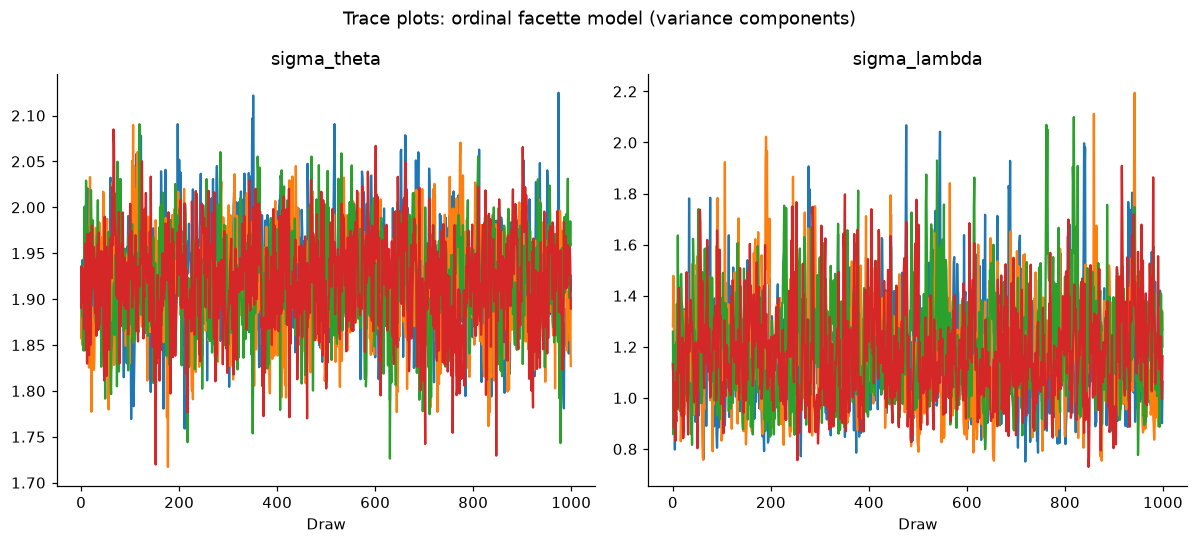

In [7]:
summary_ord = az.summary(idata_ord, var_names=["sigma_theta", "sigma_lambda", "cutpoints"],
                           round_to=4)
print(summary_ord)
save_table(summary_ord.reset_index().rename(columns={"index": "parameter"}),
            "ordinal_model_summary")

n_divergences_ord = int(idata_ord.sample_stats["diverging"].sum())
max_rhat_ord = float(summary_ord["r_hat"].max())
min_ess_ord = float(summary_ord["ess_bulk"].min())
print(f"\nDivergences: {n_divergences_ord}")
print(f"Max R-hat: {max_rhat_ord:.4f}")
print(f"Min ESS (bulk): {min_ess_ord:.0f}")

cuts_sorted = np.all(np.diff(idata_ord.posterior["cutpoints"].mean(dim=("chain", "draw")).values) > 0)
print(f"Thresholds ordered (posterior mean): {cuts_sorted}")

if max_rhat_ord >= 1.01:
    log_warning(f"Max R-hat = {max_rhat_ord:.4f} >= 1.01 for the ordinal model.")
if n_divergences_ord > 0:
    log_warning(f"{n_divergences_ord} divergences in the ordinal model.")
if not cuts_sorted:
    log_warning("Category thresholds of the ordinal model are NOT ordered at the posterior mean.")

az.plot_trace(idata_ord, var_names=["sigma_theta", "sigma_lambda"])
fig = plt.gcf()
fig.set_size_inches(11, 5)
fig.suptitle("Trace plots: ordinal facette model (variance components)")
fig.tight_layout()
save_fig(fig, "fig_mfrm_traceplots", "Trace plots of the variance components of the ordinal model.")
plt.show()

## 4. Posterior predictive checks

We check whether data replicated from the model plausibly reproduce
(a) the overall category frequencies, (b) the distribution of raw
rater means, and (c) the distribution of action means.

Sampling: [y_obs]


Figure saved: fig_mfrm_ppc.png / fig_mfrm_ppc.svg


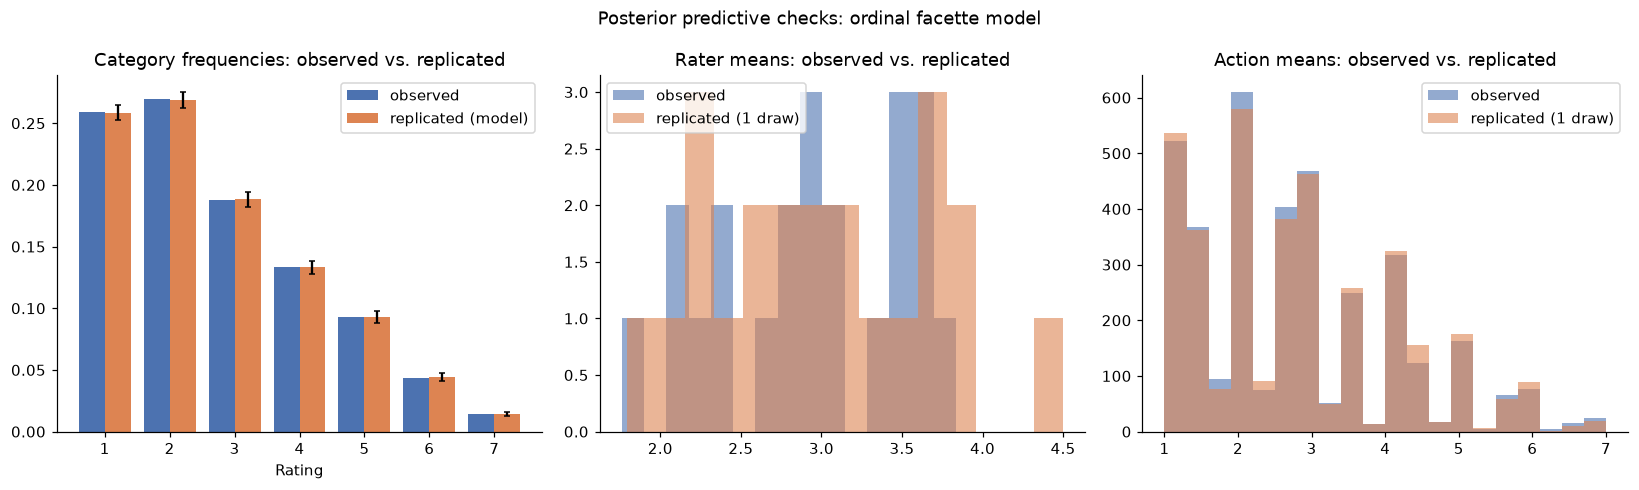

In [8]:
with ordinal_model:
    pp_ord = pm.sample_posterior_predictive(idata_ord, random_seed=SEED, progressbar=False,
                                              extend_inferencedata=False, var_names=["y_obs"])

y_rep = pp_ord.posterior_predictive["y_obs"].values  # (chain, draw, obs)
y_rep_flat_sample = y_rep[:, :100, :].reshape(-1, y_rep.shape[-1])  # subsample of draws for speed

obs_counts = np.bincount(y_ord, minlength=7) / len(y_ord)
rep_counts = np.array([np.bincount(row, minlength=7) / len(row) for row in y_rep_flat_sample])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].bar(np.arange(1, 8) - 0.2, obs_counts, width=0.4, label="observed", color="#4C72B0")
axes[0].bar(np.arange(1, 8) + 0.2, rep_counts.mean(axis=0), width=0.4, label="replicated (model)",
             color="#DD8452")
axes[0].errorbar(np.arange(1, 8) + 0.2, rep_counts.mean(axis=0),
                   yerr=rep_counts.std(axis=0), fmt="none", ecolor="black", capsize=2)
axes[0].set_title("Category frequencies: observed vs. replicated")
axes[0].set_xlabel("Rating")
axes[0].legend()

df_ord_rep = df_ord.copy()
rep_draw_example = y_rep[0, 0, :] + 1
df_ord_rep["rating_rep"] = rep_draw_example
obs_rater_means = df_ord.groupby("rater_id")["rating_numeric"].mean()
rep_rater_means = df_ord_rep.groupby("rater_id")["rating_rep"].mean()
axes[1].hist(obs_rater_means, bins=15, alpha=0.6, label="observed", color="#4C72B0")
axes[1].hist(rep_rater_means, bins=15, alpha=0.6, label="replicated (1 draw)", color="#DD8452")
axes[1].set_title("Rater means: observed vs. replicated")
axes[1].legend()

obs_action_means = df_ord.groupby("action_id")["rating_numeric"].mean()
rep_action_means = df_ord_rep.groupby("action_id")["rating_rep"].mean()
axes[2].hist(obs_action_means, bins=20, alpha=0.6, label="observed", color="#4C72B0")
axes[2].hist(rep_action_means, bins=20, alpha=0.6, label="replicated (1 draw)", color="#DD8452")
axes[2].set_title("Action means: observed vs. replicated")
axes[2].legend()

fig.suptitle("Posterior predictive checks: ordinal facette model")
fig.tight_layout()
save_fig(fig, "fig_mfrm_ppc",
         "Posterior predictive checks of the ordinal facette model: category frequencies "
         "(left, with an uncertainty band over posterior draws), rater means (middle), and "
         "action means (right), each observed vs. model-replicated data.")
plt.show()

## 5. Action scores

For each action: posterior mean/median of $\theta_i$, 95% credible
interval, posterior rank and rank uncertainty, and the **expected
observed scale value** $\mathbb E[Y_i \mid \theta_i]$ on the 1–7 scale
(stored separately from the latent score $\theta_i$, as required by
the analysis brief).

In [9]:
theta_post = idata_ord.posterior["theta"]  # dims: chain, draw, action
theta_mean = theta_post.mean(dim=("chain", "draw")).values
theta_median = theta_post.median(dim=("chain", "draw")).values
theta_low = theta_post.quantile(0.025, dim=("chain", "draw")).values
theta_high = theta_post.quantile(0.975, dim=("chain", "draw")).values
theta_sd = theta_post.std(dim=("chain", "draw")).values

# Posterior rank per draw, then mean/uncertainty of the rank
theta_flat = theta_post.values.reshape(-1, theta_post.shape[-1])  # (n_draws_total, n_action)
ranks_per_draw = theta_flat.argsort(axis=1).argsort(axis=1) + 1  # 1 = lowest creativity
rank_mean = ranks_per_draw.mean(axis=0)
rank_sd = ranks_per_draw.std(axis=0)

# Expected observed scale value E[Y|theta] under the global (posterior-mean)
# thresholds, averaged over raters (lambda=0, "average rater").
cut_mean = idata_ord.posterior["cutpoints"].mean(dim=("chain", "draw")).values

def expected_rating(theta_val, cuts):
    cum = 1 / (1 + np.exp(-(cuts - theta_val)))
    cum = np.concatenate([[0.0], cum, [1.0]])
    probs = np.diff(cum)
    return np.sum(probs * np.arange(1, 8))

expected_ratings = np.array([expected_rating(t, cut_mean) for t in theta_mean])

ordinal_scores = pd.DataFrame({
    "action_id": action_levels_o,
    "ordinal_latent_score": theta_mean,
    "ordinal_latent_median": theta_median,
    "ordinal_latent_sd": theta_sd,
    "ordinal_latent_lower": theta_low,
    "ordinal_latent_upper": theta_high,
    "ordinal_posterior_rank_mean": rank_mean,
    "ordinal_posterior_rank_sd": rank_sd,
    "ordinal_expected_rating": expected_ratings,
})
save_table(ordinal_scores, "ordinal_action_scores")
print(f"Ordinal action scores computed for {len(ordinal_scores)} actions.")
ordinal_scores.head()

Table saved: results/tables/ordinal_action_scores.csv (3669 rows x 9 columns)
Ordinal action scores computed for 3669 actions.


,action_id,ordinal_latent_score,ordinal_latent_median,ordinal_latent_sd,ordinal_latent_lower,ordinal_latent_upper,ordinal_posterior_rank_mean,ordinal_posterior_rank_sd,ordinal_expected_rating
0,0786bb62-2032-444b-ac1f-59fa165dbb71,-2.793971,-2.776204,1.260286,-5.398700,-0.468257,404.46750,412.933894,1.536369
1,f90addfa-4cf8-4b07-a4eb-9ee7ff757519,-0.211932,-0.213566,0.859230,-1.881115,1.464646,1700.67000,601.990584,2.821990
2,2bdc8133-ac12-45f1-9104-882873efa7bf,0.099323,0.107814,0.912691,-1.805582,1.911207,1918.75575,630.706226,3.017251
3,938d2c93-5e6f-442e-ba7c-f92c53080a42,0.297014,0.310760,1.118274,-1.933839,2.470226,2044.58475,736.289778,3.144486
4,4fe7a32b-09ce-466b-9772-494ed03ea493,2.602362,2.687114,1.552471,-0.606396,5.414566,3137.75325,608.020580,4.685413


## 6. Rater severity

$\lambda_j$ on the logit scale (positive = more lenient), with 95% credible
intervals.

Table saved: results/tables/mfrm_rater_severity.csv (22 rows x 5 columns)


Figure saved: fig_mfrm_rater_severity.png / fig_mfrm_rater_severity.svg


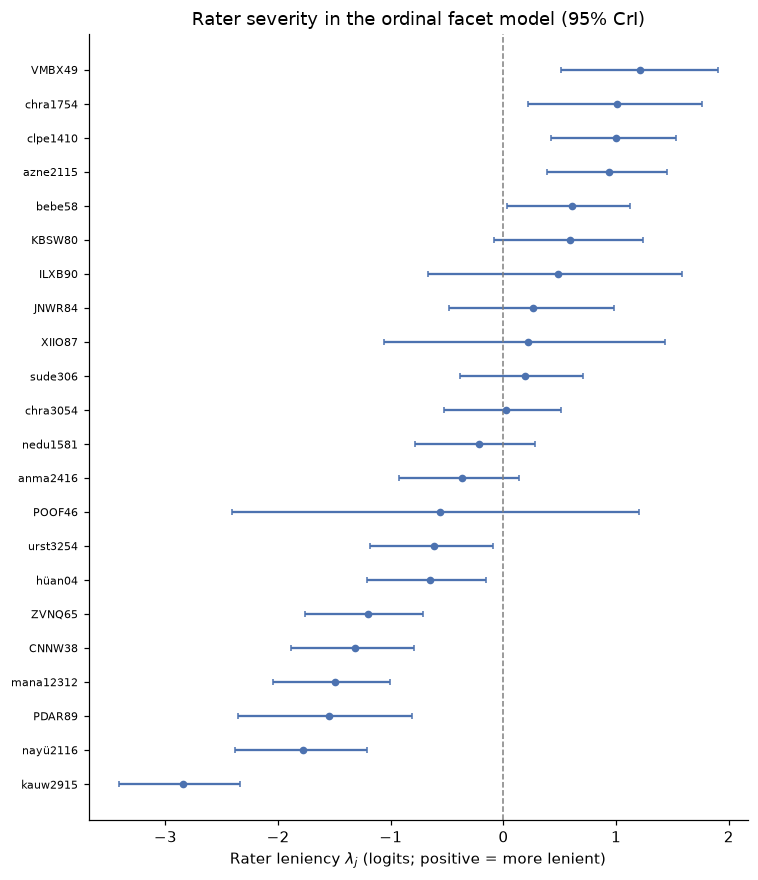

In [10]:
lam_post = idata_ord.posterior["lam"]
lam_mean = lam_post.mean(dim=("chain", "draw")).values
lam_sd = lam_post.std(dim=("chain", "draw")).values
lam_low = lam_post.quantile(0.025, dim=("chain", "draw")).values
lam_high = lam_post.quantile(0.975, dim=("chain", "draw")).values

ordinal_severity = pd.DataFrame({
    "rater_id": rater_levels_o,
    "ordinal_severity": lam_mean,
    "ordinal_severity_sd": lam_sd,
    "ordinal_severity_lower": lam_low,
    "ordinal_severity_upper": lam_high,
}).sort_values("ordinal_severity").reset_index(drop=True)
save_table(ordinal_severity, "mfrm_rater_severity")

fig, ax = plt.subplots(figsize=(7, 0.3 * len(ordinal_severity) + 1.5))
y_pos = np.arange(len(ordinal_severity))
ax.errorbar(ordinal_severity["ordinal_severity"], y_pos,
            xerr=[ordinal_severity["ordinal_severity"] - ordinal_severity["ordinal_severity_lower"],
                  ordinal_severity["ordinal_severity_upper"] - ordinal_severity["ordinal_severity"]],
            fmt="o", ms=4, color="#4C72B0", capsize=2)
ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(ordinal_severity["rater_id"], fontsize=7)
ax.set_xlabel(r"Rater leniency $\lambda_j$ (logits; positive = more lenient)")
ax.set_title("Rater severity in the ordinal facet model (95% CrI)")
fig.tight_layout()
save_fig(fig, "fig_mfrm_rater_severity",
         "Rater severity (leniency) on the logit scale of the ordinal facet model, "
         "posterior means with 95% credible intervals.")
plt.show()

## 7. Rater and action fit (infit / outfit)

The standard MFRM rater-fit statistics (Wright & Masters, 1982; Eckes, 2015)
compare each observed rating $x$ with its model-expected value
$E = \sum_k k\,P_k$ and variance $W = \sum_k (k-E)^2 P_k$, computed at the
posterior-mean parameters:

$$
\text{Outfit}_j = \frac{1}{n_j}\sum_i \frac{(x_{ij}-E_{ij})^2}{W_{ij}}, \qquad
\text{Infit}_j = \frac{\sum_i (x_{ij}-E_{ij})^2}{\sum_i W_{ij}}
$$

Both have expectation 1.
- **Values well above 1** mean more noise than the model predicts:
  idiosyncratic or erratic ratings.
- **Values well below 1** mean less variation than predicted:
  overly predictable ratings, often central-tendency or halo-like behaviour.
- **Outfit** is sensitive to unexpected ratings far from the rater's typical
  range. **Infit** is information-weighted and less affected by outliers.

The often-cited range 0.5–1.5 (Linacre) is drawn for orientation only. It is
not used as a hard cut-off. These are Rasch-style analogues computed under the
cumulative-logit link.

Table saved: results/tables/mfrm_rater_fit.csv (22 rows x 4 columns)
Rater fit (sorted by infit):
 rater_id  n_ratings  infit_mnsq  outfit_mnsq
   bebe58      264.0    0.257793     0.268957
mana12312     1174.0    0.358841     0.366297
 clpe1410      254.0    0.408779     0.406964
  sude306      383.0    0.442737     0.425935
   JNWR84       52.0    0.463284     0.461666
 chra3054      522.0    0.561597     0.556081
 anma2416      720.0    0.611735     0.608981
 nayü2116      259.0    0.641679     0.565028
   hüan04      633.0    0.709386     0.669627
 urst3254      620.0    0.713967     0.665640
   KBSW80       73.0    0.743143     0.687917
 chra1754       50.0    0.762043     0.788869
 kauw2915      520.0    0.764423     0.569058
   ZVNQ65      547.0    0.771983     0.686636
 nedu1581      873.0    0.849212     0.812298
   POOF46        2.0    0.888802     0.886701
   CNNW38      369.0    0.928555     0.881572
   VMBX49       55.0    1.035530     1.117790
 azne2115      400.0    1.04

Figure saved: fig_mfrm_rater_fit.png / fig_mfrm_rater_fit.svg


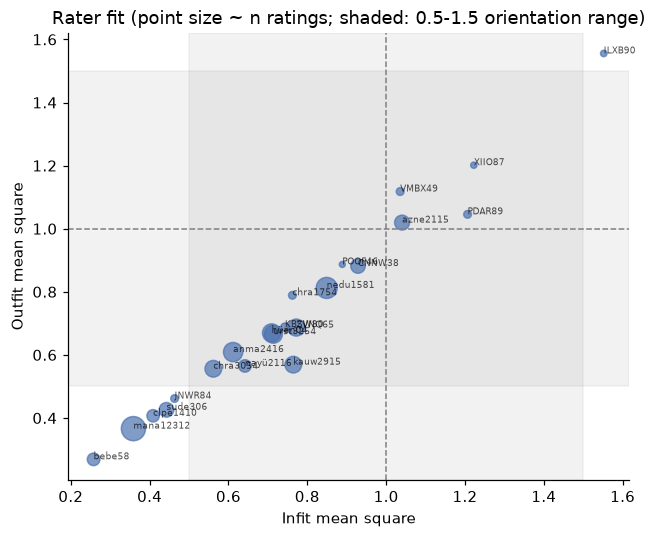

In [11]:
cats = np.arange(1, 8)
eta_hat = theta_mean[action_idx_o] + lam_mean[rater_idx_o]
cum = 1 / (1 + np.exp(-(cut_mean[None, :] - eta_hat[:, None])))  # P(Y <= k), k = 1..6
cum = np.concatenate([np.zeros((len(eta_hat), 1)), cum, np.ones((len(eta_hat), 1))], axis=1)
probs_hat = np.diff(cum, axis=1)                                   # (n_obs, 7)

expected_x = probs_hat @ cats
variance_x = probs_hat @ cats ** 2 - expected_x ** 2
x_obs = df_ord["rating_numeric"].values
sq_resid = (x_obs - expected_x) ** 2

fit_obs = pd.DataFrame({"rater_id": df_ord["rater_id"].values,
                        "action_id": df_ord["action_id"].values,
                        "sq_resid": sq_resid, "w": variance_x,
                        "z2": sq_resid / variance_x})

def fit_stats(g):
    return pd.Series({"n_ratings": len(g),
                      "infit_mnsq": g["sq_resid"].sum() / g["w"].sum(),
                      "outfit_mnsq": g["z2"].mean()})

rater_fit = fit_obs.groupby("rater_id").apply(fit_stats, include_groups=False).reset_index()
action_fit = fit_obs.groupby("action_id").apply(fit_stats, include_groups=False).reset_index()
save_table(rater_fit, "mfrm_rater_fit")

print("Rater fit (sorted by infit):")
print(rater_fit.sort_values("infit_mnsq").to_string(index=False))
print("\nAction fit (actions with >= 3 ratings), distribution:")
print(action_fit.loc[action_fit["n_ratings"] >= 3, ["infit_mnsq", "outfit_mnsq"]].describe().round(2))

fig, ax = plt.subplots(figsize=(6, 5))
ax.axvspan(0.5, 1.5, color="grey", alpha=0.1)
ax.axhspan(0.5, 1.5, color="grey", alpha=0.1)
ax.scatter(rater_fit["infit_mnsq"], rater_fit["outfit_mnsq"],
           s=15 + rater_fit["n_ratings"] / 5, alpha=0.7, color="#4C72B0")
for _, r in rater_fit.iterrows():
    ax.annotate(r["rater_id"], (r["infit_mnsq"], r["outfit_mnsq"]), fontsize=6, alpha=0.7)
ax.axvline(1, color="grey", ls="--", lw=1)
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xlabel("Infit mean square")
ax.set_ylabel("Outfit mean square")
ax.set_title("Rater fit (point size ~ n ratings; shaded: 0.5-1.5 orientation range)")
fig.tight_layout()
save_fig(fig, "fig_mfrm_rater_fit",
         "Infit vs. outfit mean-square statistics per rater from the ordinal facet model; "
         "the shaded band marks the conventional 0.5-1.5 orientation range.")
plt.show()

## 8. Separation reliability

Following Eckes (2015), for each facet:

$$
R = \frac{\operatorname{Var}(\hat\beta) - \overline{\mathrm{PSD}^2}}{\operatorname{Var}(\hat\beta)},
\qquad G = \sqrt{\frac{R}{1-R}}, \qquad H = \frac{4G+1}{3}
$$

R is the separation reliability, G the separation index and H the number of
statistically distinct strata.

- **Actions.** $R$ is the reliability of the creativity scores: how reliably
  the actions are told apart. It should be high.
- **Raters.** $R$ is how reliably the raters differ in severity. A high value
  is *not* good news: it means that rater severity differences are real and
  must be corrected for.

The empirical reliability $\operatorname{Var}(\hat\theta)/[\operatorname{Var}(\hat\theta)+\overline{\mathrm{PSD}^2}]$
is also reported, for comparability with `02b` and `02d`.

In [12]:
def separation(est, psd):
    obs_var = np.var(est, ddof=1)
    err_var = np.mean(psd ** 2)
    true_var = max(obs_var - err_var, 0.0)
    R = true_var / obs_var
    G = np.sqrt(true_var / err_var)
    return {"separation_reliability": R, "separation_index": G, "strata": (4 * G + 1) / 3,
            "empirical_reliability": obs_var / (obs_var + err_var)}

separation_df = pd.DataFrame([
    {"facet": "actions (theta)", **separation(theta_mean, theta_sd)},
    {"facet": "raters (lambda)", **separation(lam_post.mean(dim=("chain", "draw")).values,
                                             lam_post.std(dim=("chain", "draw")).values)},
])
save_table(separation_df, "mfrm_separation")
separation_df

Table saved: results/tables/mfrm_separation.csv (2 rows x 5 columns)


,facet,separation_reliability,separation_index,strata,empirical_reliability
0,actions (theta),0.437441,0.881812,1.509083,0.639976
1,raters (lambda),0.870265,2.589987,3.786649,0.885163


## 9. Proportional-odds assumption

The cumulative logit model assumes **common** (not rater- or
category-specific) thresholds ("proportional odds"). Given the current
model structure, this assumption cannot be tested directly without
estimating an extended variant (e.g., rater-specific threshold shifts
or rater-specific discrimination). We address this in `02d_judge_response_theory.ipynb` via a
judge-response-theory model with **rater-specific discrimination** and
formally compare both models via LOO-CV. A fully separate
adjacent-category sensitivity analysis is not additionally estimated
for reasons of compute time and connectivity (see the analysis brief's
warning: "avoid unnecessarily complex models when data connectivity
... is insufficient").

## 10. Export in the standard format

`score` is the posterior mean of the latent θ (logits). The expected rating on
the 1–7 scale for an average rater ($\lambda = 0$) is kept as
`expected_rating`. Actions outside the largest component get `NaN`.

In [13]:
scores_mfrm = ordinal_scores.rename(columns={
    "ordinal_latent_score": "score", "ordinal_latent_sd": "score_se",
    "ordinal_latent_lower": "score_lower", "ordinal_latent_upper": "score_upper",
    "ordinal_latent_median": "score_median", "ordinal_expected_rating": "expected_rating",
    "ordinal_posterior_rank_mean": "posterior_rank_mean", "ordinal_posterior_rank_sd": "posterior_rank_sd",
})
action_base = (ratings_clean.groupby("action_id")
               .agg(n_ratings=("rating_numeric", "size"),
                    connected_component=("connected_component", "first"))
               .reset_index())
action_base["in_largest_component"] = action_base["connected_component"] == 0
scores_mfrm = action_base.merge(scores_mfrm, on="action_id", how="left").merge(
    action_fit.drop(columns="n_ratings"), on="action_id", how="left")
save_table(scores_mfrm, "scores_mfrm")

raters_mfrm = ordinal_severity.rename(columns={
    "ordinal_severity": "severity", "ordinal_severity_sd": "severity_se",
    "ordinal_severity_lower": "severity_lower", "ordinal_severity_upper": "severity_upper",
}).merge(rater_fit, on="rater_id", how="left")
save_table(raters_mfrm, "raters_mfrm")

sep = separation_df.set_index("facet")
save_diagnostics({
    "max_rhat": max_rhat_ord, "n_divergences": n_divergences_ord, "min_ess_bulk": min_ess_ord,
    "thresholds_ordered": cuts_sorted,
    "sigma_theta": float(idata_ord.posterior["sigma_theta"].mean()),
    "sigma_lambda": float(idata_ord.posterior["sigma_lambda"].mean()),
    "action_separation_reliability": sep.loc["actions (theta)", "separation_reliability"],
    "action_strata": sep.loc["actions (theta)", "strata"],
    "rater_separation_reliability": sep.loc["raters (lambda)", "separation_reliability"],
    "empirical_reliability": sep.loc["actions (theta)", "empirical_reliability"],
    "n_raters_infit_outside_0.5_1.5": int((~rater_fit["infit_mnsq"].between(0.5, 1.5)).sum()),
    "n_raters_outfit_outside_0.5_1.5": int((~rater_fit["outfit_mnsq"].between(0.5, 1.5)).sum()),
    "n_components": n_components,
})

Table saved: results/tables/scores_mfrm.csv (3669 rows x 14 columns)
Table saved: results/tables/raters_mfrm.csv (22 rows x 8 columns)
Table saved: results/tables/model_diagnostics_mfrm.csv (13 rows x 2 columns)


PosixPath('/home/max/drive/projects/3_Creativity/11-paper-CAT-methodology/data-analysis/creativity-ratings-psychometrics/results/tables/model_diagnostics_mfrm.csv')

## Warnings collected in this notebook

In [14]:
warnings_df = pd.DataFrame(WARNINGS_LOG, columns=["notebook", "timestamp", "message"])
save_table(warnings_df, f"warnings_log_{NOTEBOOK_KEY}")
print(f"{len(warnings_df)} warnings collected in this notebook.")
for msg in warnings_df["message"]:
    print(f"  - {msg}")

Table saved: results/tables/warnings_log_mfrm.csv (0 rows x 3 columns)
0 warnings collected in this notebook.
